# Binned base learners

A P-spline learner normally retains one basis row per observation. That representation is exact, but its memory grows as `n * d` for every learner, where `n` is the row count and `d` is the basis dimension. Quantile binning replaces repeated or nearby basis rows with one representative row per occupied bin. The boosting estimator then operates on the compact basis until one learner is selected; only that learner's fitted values are gathered back to observation order.

The construction adapts the discretization used for large additive models {cite:p}`wood2017gigadata` to component-wise boosting. Binning changes the learner design and is therefore an approximation unless every distinct covariate value receives its own bin. It does not change the family loss, boosting update, penalty, or stopping rule.

In [1]:
import json
import pathlib

import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

ROOT = next(path for path in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (path / "pyproject.toml").exists())
benchmark = json.loads((ROOT / "benches" / "binned_base_learners.json").read_text())
bbs_exact_mb = benchmark["retained_learner_bytes"]["bbs"]["exact"] / 1e6
bbs_k100_mb = benchmark["retained_learner_bytes"]["bbs"]["K100"] / 1e6
bbs_speed_ratio = (benchmark["criterion_median_ms"]["bbs"]["exact"] /
                   benchmark["criterion_median_ms"]["bbs"]["K100"])
selection_gate = benchmark["selection_sequence_gate"]
print(f"BBS retained data: {bbs_exact_mb:.1f} MB exact, {bbs_k100_mb:.2f} MB at K=100")
print(f"BBS fit-time ratio: {bbs_speed_ratio:.2f}x")

BBS retained data: 720.0 MB exact, 4.23 MB at K=100
BBS fit-time ratio: 6.03x


## Storage of dense P-spline designs

Let `X_j` be the `n x d_j` design of learner `j`. A cubic B-spline row has local support, but the exact implementation still retains the dense design, its weighted transpose, and kernel-specific copies. On the recorded benchmark with {eval}`benchmark['configuration']['n']` observations, ten spline learners retain {eval}`f"{bbs_exact_mb:.1f} MB"` of learner data. The compact representation with one hundred requested bins retains {eval}`f"{bbs_k100_mb:.2f} MB"`.

The reduction is larger than the ratio `n / K` alone suggests because the exact block learner retains several observation-sized matrices. The compact learner retains one `u32` bin index per observation, one `K x d_j` basis, weight-dependent bin work arrays, and the small penalty and factorization.

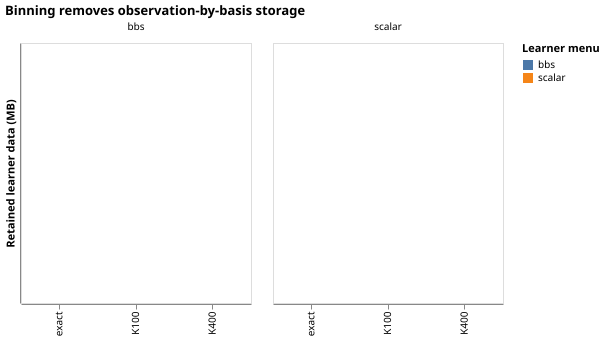

In [2]:
rows = []
for learner in ("scalar", "bbs"):
    for representation in ("exact", "K100", "K400"):
        rows.append({
            "learner": learner,
            "representation": representation,
            "retained MB": benchmark["retained_learner_bytes"][learner][representation] / 1e6,
            "fit ms": benchmark["criterion_median_ms"][learner][representation],
        })
storage = pl.DataFrame(rows)
memory_chart = alt.Chart(storage, title="Binning removes observation-by-basis storage").mark_bar().encode(
    x=alt.X("representation:N", title=None, sort=["exact", "K100", "K400"]),
    y=alt.Y("retained MB:Q", title="Retained learner data (MB)", scale=alt.Scale(type="log")),
    color=alt.Color("learner:N", title="Learner menu"),
    column=alt.Column("learner:N", title=None),
).properties(width=230, height=260)
memory_chart

## Quantile binning

For one continuous covariate, the preparation step sorts its distinct values and assigns tied runs to observation-count quantiles. Equal values are never split. A large tied run can cross several requested cutpoints, so the effective bin count can be smaller than `K`; the compact basis stores only occupied cells. Each bin representative is the unweighted mean of its observations. Keeping representatives independent of fitting weights lets bootstrap and stability-selection folds share one bin structure (stability selection refits the model on many half-samples and keeps the terms selected in more than a cutoff share of them).

When `K` is at least the number of distinct values, each distinct value receives one cell. The binned design then equals the exact design mathematically. The engine tests check that, under that condition, the binned fit selects the same learners in the same order and has the same fitted values and risk as the exact fit.

## Bin-space identities for the Gram matrix and right-hand side

Let `c_j(i)` be observation `i`'s bin, `B_j` the `K_j x d_j` basis at bin representatives, `w_i` the prior weight, and `u_i` the current negative gradient. Define the bin weight and weighted-gradient sums

$$n_{jk} = \sum_{i:c_j(i)=k} w_i, \qquad \tilde u_{jk} = \sum_{i:c_j(i)=k} w_i u_i.$$

The weighted Gram and right-hand side are then

$$X_j^\top W X_j = B_j^\top \operatorname{diag}(n_j) B_j, \qquad X_j^\top W u = B_j^\top \tilde u_j.$$

For ridge penalty `P_j`, the learner solves

$$\hat\beta_j = \left(B_j^\top \operatorname{diag}(n_j) B_j + P_j\right)^{-1} B_j^\top \tilde u_j.$$

Candidate selection needs no observation-length prediction. With `g_j = B_j^T \tilde u_j`, stationarity gives

$$\operatorname{SSE}_j = u^\top W u - \hat\beta_j^\top g_j - \hat\beta_j^\top P_j \hat\beta_j.$$

After selecting `j*`, the engine computes the `K_{j*}` fitted bin values and gathers `B_{j*}[c_{j*}(i), :] \hat\beta_{j*}` once. Losing learners never materialize an `n`-vector prediction.

In [3]:
# The identities are ordinary weighted least squares after grouping rows.
bin_index = np.array([0, 0, 1, 1, 1, 2, 2, 2, 2], dtype=int)
basis = np.array([[1.0, -1.0], [1.0, 0.2], [1.0, 1.3]])
weights = np.array([1.0, 0.5, 2.0, 1.0, 0.7, 0.4, 1.5, 0.8, 1.2])
gradient = np.array([0.2, -0.1, 0.8, 0.4, -0.3, 1.1, 0.7, -0.2, 0.5])
penalty = np.diag([0.0, 0.4])
design = basis[bin_index]
bin_weights = np.bincount(bin_index, weights=weights)
bin_gradient = np.bincount(bin_index, weights=weights * gradient)
gram_dense = design.T @ (weights[:, None] * design)
gram_binned = basis.T @ (bin_weights[:, None] * basis)
rhs_dense = design.T @ (weights * gradient)
rhs_binned = basis.T @ bin_gradient
beta = np.linalg.solve(gram_binned + penalty, rhs_binned)
prediction = design @ beta
sse_explicit = np.sum(weights * (gradient - prediction) ** 2)
sse_identity = np.sum(weights * gradient ** 2) - beta @ rhs_binned - beta @ penalty @ beta
identity_error = max(
    np.abs(gram_dense - gram_binned).max(),
    np.abs(rhs_dense - rhs_binned).max(),
    abs(sse_explicit - sse_identity),
)
print(f"maximum identity error: {identity_error:.3e}")

maximum identity error: 1.776e-15


The maximum discrepancy is {eval}`f"{identity_error:.1e}"`, at floating-point reduction precision. The algebra is exact for the discretized design; approximation enters only when several distinct covariate values share one representative.

## Blueprints and fold-specific state

`LearnerBlueprint` owns weight-independent state (state that does not depend on the observation weights). A binned blueprint holds its `Arc<[u32]>` observation index, representatives, cutpoints, compact basis, penalty template, and new-data replay recipe. `cvrisk` and stability selection share those arrays across folds.

`PreparedLearner` owns fold-specific state: bin weight sums, centered compact bases where centering depends on weights, the penalized Gram solver, and reusable right-hand-side and coefficient buffers. This separation avoids rebuilding bin membership during resampling while preserving each fold's prior weights and smoothing parameter.

`BinnedScalarBols` specializes the one-column solve. `BinnedBlockBols` handles P-splines, exact compact random effects, and occupied spatial cells. The general boosting loop calls the same `fit_step_select` and `predict_into` interface used by exact block learners.

## Public API: `bins=`

A per-learner value controls local accuracy:

```python
mb.Bbs("temperature", bins=400)
mb.Bols("price", intercept=False, bins=400)
mb.Bspatial("longitude", "latitude", bins=40)  # per axis
mb.Brandom("site", bins=200)  # must cover every observed level
```

`gamboost(..., bins=400)` supplies a default to supported learners; an explicit learner value takes precedence. Linear `bols` binning currently requires `intercept=False`, and varying-coefficient `by=` terms (a term multiplied by a covariate z, so that its effect varies with z) remain exact. Shape-constrained splines also remain exact because their iterative or active-set solve needs additional constraint-state work not yet implemented in bin space (the design with one row per occupied bin).

For `bspatial`, `K` is the count per coordinate axis. The implementation stores only occupied joint cells, not a dense `K x K` grid. For `brandom`, levels are never merged; requesting fewer bins than observed levels raises an error.

In [4]:
rng = np.random.default_rng(4)
n_demo = 50_000
demo = {"x": rng.random(n_demo)}
demo["y"] = np.sin(2 * np.pi * demo["x"]) + rng.normal(scale=0.25, size=n_demo)
demo_fit = mb.gamboost(
    "y ~ bbs(x, center=True)", data=demo, bins=100,
    family=mb.Gaussian(), control=mb.boost_control(80, 0.1),
)
demo_report = demo_fit.execution_report()
demo_check = demo_fit.check_binning(n=5_000, mstop=60, seed=9)
pl.DataFrame([{
    "retained learner MB": demo_report.retained_learner_bytes / 1e6,
    "max difference / residual SD": demo_check["relative_to_residual_sd"],
    "first selection divergence": demo_check["first_selection_divergence"],
}])

retained learner MB,max difference / residual SD,first selection divergence
f64,f64,null
0.223424,0.256432,null


## Accuracy check: `check_binning`

`check_binning()` draws one matched subsample, refits the compact and exact learner menus to the same stopping iteration, and reports the maximum fitted-value difference relative to the exact residual standard deviation. It also identifies the first selection-path divergence. The comparison holds the rows, family, weights, learner penalties, step length, and stopping budget fixed.

The diagnostic does not prove that the full-data paths are identical. It measures whether discretization is small relative to residual variation on a reconstruction-sized problem. Increasing `K` is warranted when the relative discrepancy is material or the path diverges before the region used for interpretation.

The moderate-size check uses {eval}`selection_gate['n']` observations, {eval}`selection_gate['learners']` spline learners and {eval}`selection_gate['bins']` requested bins. The check passes when its {eval}`selection_gate['mstop']`-iteration selection sequence is identical; here that sequence is identical, and the maximum fitted difference is {eval}`f"{selection_gate['max_abs_fitted_difference']:.3f}"`. Selection identity is a stronger discrete-path check; fitted discrepancy describes the approximation that remains within the selected learners.

## Gaussian cross-tabulation cache

For squared-error loss, every learner's bin-gradient sums could be updated from pairwise cross-tabulations after the selected learner changes the residual. That would remove candidate scatter passes from later iterations. The cache grows with learner pairs and joint occupied cells, so it can replace an `O(n)` scan with an `O(p^2)` memory problem. The current implementation keeps this path disabled: compact splines already reduce the recorded fit time by {eval}`f"{bbs_speed_ratio:.1f}x"`, and no pairwise cache is allocated.

The ordinary Gaussian Gram route remains available to exact all-linear models. Opt-in binning takes the general compact route. This keeps the memory choice explicit rather than selecting a large cross-cache from family name alone.

## See also

- [](engine.ipynb) describes candidate selection and the exact Gaussian Gram route.
- [](base_learners.ipynb) describes exact learner preparation and penalties.
- [](performance.ipynb) documents the benchmark settings, timing procedures and saved results.
- [](../cases/million_rows_binned.ipynb) applies the compact path to one million observations.

```{bibliography}
:filter: docname in docnames
```